# ENGINEERING MATHEMATICS: DIFFERENTIAL EQUATIONS — 1125

## Chapter 11: Fourier Series

Chapter 6 built solutions out of the powers $1$, $x$, $x^2$, $\ldots$  
A power series is fitted at a single point:  
its coefficients are the derivatives $f^{(n)}(a)/n!$,  
so the function must be analytic there,  
and the series may still diverge far from the center.

This chapter builds functions out of $1$, $\cos nx$, and $\sin nx$ instead.  
The coefficients are integrals over a whole interval,  
so the series can represent functions with corners and jumps,  
such as a voltage that is switched on and off.

Fourier introduced these series around 1807  
to study heat conduction.  
In Chapter 12 they solve partial differential equations,  
such as the heat equation and the wave equation.

- 11.1: orthogonal functions, which make the coefficients easy to find.
- 11.2: Fourier series, the expansion in cosines and sines.

## 11.1 Orthogonal Functions

### Components from dot products

Let $\mathbf v_1$, $\mathbf v_2$, $\mathbf v_3$
be nonzero vectors in $\mathbb R^3$  
that are mutually orthogonal:  
$\mathbf v_i \cdot \mathbf v_j = 0$ for $i \ne j$.  
Every vector $\mathbf u$ is a combination
$$ \mathbf u = c_1 \mathbf v_1 + c_2 \mathbf v_2 + c_3 \mathbf v_3. $$

Dot both sides with $\mathbf v_1$:  
the terms with $\mathbf v_2$ and $\mathbf v_3$ vanish,  
so $\mathbf u \cdot \mathbf v_1 = c_1 \|\mathbf v_1\|^2$.  
In the same way,
$$ c_i = \frac{\mathbf u \cdot \mathbf v_i}{\|\mathbf v_i\|^2}, \qquad i = 1, 2, 3. $$

Each coefficient comes from one dot product,  
without solving a system of equations.  
This section does the same with functions in place of vectors.

### The inner product of functions

The dot product $\mathbf u \cdot \mathbf v = \sum u_i v_i$  
multiplies matching components and adds.  
For functions on $[a, b]$,  
the values $f(x)$ play the role of components,  
and the sum becomes an integral.

The **inner product** of $f_1$ and $f_2$ on $[a, b]$ is
$$ (f_1, f_2) = \int_a^b f_1(x) f_2(x)\,dx. $$
Like the dot product, it is symmetric and linear:  
$(f_1, f_2) = (f_2, f_1)$  
and $(kf_1 + f_2, f_3) = k(f_1, f_3) + (f_2, f_3)$.

Also $(f, f) = \int_a^b f(x)^2\,dx \ge 0$,  
and for a continuous $f$ it is $0$ only when $f = 0$.

A Riemann sum makes the analogy concrete.  
With $N$ equally spaced points $x_i$ and $\Delta x = (b - a)/N$,
$$ (f_1, f_2) \approx \sum_{i=1}^N f_1(x_i) f_2(x_i) \Delta x, $$
the dot product of the two lists of sampled values, times $\Delta x$.

### Orthogonal functions

Two functions $f_1$ and $f_2$ are **orthogonal** on $[a, b]$  
if $(f_1, f_2) = 0$.  
The word is borrowed from vectors;  
there is no right angle to draw.  
The zero function is orthogonal to every function.

### Example 1: powers on $[-1, 1]$

The functions $x^2$ and $x^3$ are orthogonal on $[-1, 1]$:
$$ (x^2, x^3) = \int_{-1}^1 x^5\,dx = 0, $$
since $x^5$ is odd.

But $x^2$ and $x^4$ are not:
$$ (x^2, x^4) = \int_{-1}^1 x^6\,dx = \frac27. $$

Orthogonality also depends on the interval.  
On $[0, 1]$,
$$ (x^2, x^3) = \int_0^1 x^5\,dx = \frac16 \ne 0. $$

### Orthogonal sets

A set of functions $\{\phi_0, \phi_1, \phi_2, \ldots\}$  
is **orthogonal** on $[a, b]$  
if every two different members are orthogonal:
$$ (\phi_m, \phi_n) = \int_a^b \phi_m(x) \phi_n(x)\,dx = 0, \qquad m \ne n. $$

### Example 2: $\{1, \cos x, \cos 2x, \ldots\}$ on $[-\pi, \pi]$

Take $\phi_0 = 1$ and $\phi_n = \cos nx$.  
For $n \ge 1$,
$$ (\phi_0, \phi_n) = \int_{-\pi}^\pi \cos(nx)\,dx = \Bigl[\frac{\sin nx}{n}\Bigr]_{-\pi}^\pi = 0, $$
since $\sin n\pi = 0$ for every integer $n$.

For $m \ne n$, the product-to-sum identity gives
$$ \begin{aligned}
(\phi_m, \phi_n) &= \int_{-\pi}^\pi \cos(mx)\cos(nx)\,dx \\
&= \frac12 \int_{-\pi}^\pi \Bigl(\cos\bigl((m + n)x\bigr) + \cos\bigl((m - n)x\bigr)\Bigr)\,dx,
\end{aligned} $$
which is $0$, since $m + n$ and $m - n$ are nonzero integers.

#### Picture: positive and negative areas cancel

The integral of $\cos(x)\cos(2x)$ over $[-\pi, \pi]$  
is its area above the axis minus its area below.  
Compare it with $\cos(2x)^2$, which is never negative.

In [1]:
import numpy as np
x = SR.var('x')

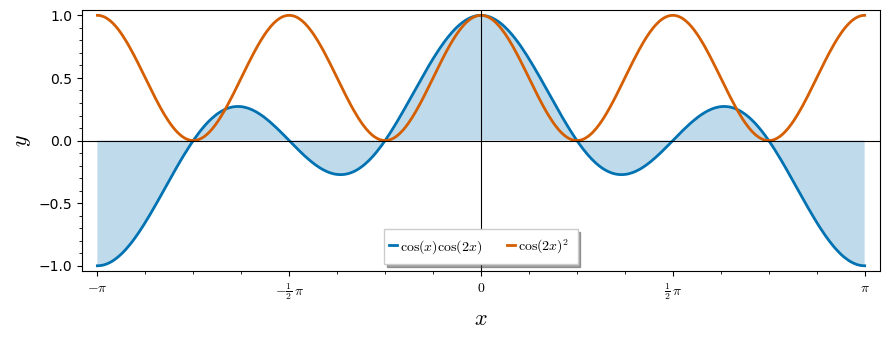

In [2]:
area_plot = plot(cos(x)*cos(2*x), (x, -pi, pi), color='#0072B2', thickness=2, fill='axis',
                 fillcolor='#0072B2', fillalpha=0.25, legend_label=r'$\cos(x)\cos(2x)$')
area_plot += plot(cos(2*x)**2, (x, -pi, pi), color='#D55E00', thickness=2,
                  legend_label=r'$\cos(2x)^2$')
area_plot.show(figsize=[9, 3.5], frame=True, axes=True, axes_labels=['$x$', '$y$'],
               ticks=[pi/2, 0.5], tick_formatter=[pi, None], legend_options={'loc': 'lower center', 'ncol': 2})

**Read the picture:**  
the shaded lobes of $\cos(x)\cos(2x)$ above and below the axis  
have equal areas, so the integral is $0$.  
The curve $\cos(2x)^2$ stays above the axis  
and oscillates around $\frac12$, so its integral is $\frac12 \cdot 2\pi = \pi$.

### Norms and orthonormal sets

The **norm** of a function is $\|f\| = \sqrt{(f, f)}$,  
the analogue of the length of a vector:
$$ \|f\|^2 = \int_a^b f(x)^2\,dx. $$
An orthogonal set is **orthonormal**  
if every member has norm $1$.

### Example 3: the norms in Example 2

For $\phi_0 = 1$, $\|1\|^2 = \int_{-\pi}^\pi dx = 2\pi$.  
For $n \ge 1$, the identity $\cos(\theta)^2 = \frac12(1 + \cos2\theta)$ gives
$$ \|\cos nx\|^2 = \frac12 \int_{-\pi}^\pi (1 + \cos2nx)\,dx = \pi. $$
So $\|1\| = \sqrt{2\pi}$ and $\|\cos nx\| = \sqrt\pi$.

Dividing each function by its norm gives the orthonormal set
$$ \Bigl\{\frac1{\sqrt{2\pi}}, \frac{\cos x}{\sqrt\pi}, \frac{\cos2x}{\sqrt\pi}, \ldots\Bigr\}. $$
The constant $1$ has the larger norm:  
$1^2 = 1$, while $\cos(nx)^2$ averages only $\frac12$.

### Orthogonality from a differential equation

Trigonometric identities prove orthogonality case by case;  
a differential equation explains it.  
For $n = 1, 2, 3, \ldots$, the function $\phi_n = \sin nx$ solves
$$ \phi'' + n^2 \phi = 0, \qquad \phi(0) = \phi(\pi) = 0. $$

Multiply the equation for $\phi_m$ by $\phi_n$,  
the equation for $\phi_n$ by $\phi_m$, and subtract:
$$ \phi_m'' \phi_n - \phi_m \phi_n'' = (n^2 - m^2) \phi_m \phi_n. $$
The left-hand side is the derivative of $\phi_m' \phi_n - \phi_m \phi_n'$.

Integrate from $0$ to $\pi$:
$$ (n^2 - m^2) \int_0^\pi \phi_m \phi_n\,dx = \Bigl[\phi_m' \phi_n - \phi_m \phi_n'\Bigr]_0^\pi = 0, $$
because every $\phi_n$ vanishes at both ends.  
So $\sin mx$ and $\sin nx$ are orthogonal on $[0, \pi]$ when $m \ne n$.

The proof used only the equation and the boundary values,  
not the formula $\sin nx$.  
In Chapter 12, orthogonal sets arise in exactly this way,  
from boundary-value problems.

### Example 4: Legendre polynomials

Recall that in 1118 we found that Legendre's equation
$$ (1 - x^2) y'' - 2xy' + n(n + 1) y = 0 $$
has a polynomial solution of degree $n$ for each $n = 0, 1, 2, \ldots$  
Scaled so that its value at $x = 1$ is $1$,  
it is the **Legendre polynomial** $P_n$.

The first four are
$$ \begin{aligned}
P_0 &= 1, & P_2 &= \frac{3x^2 - 1}{2}, \\
P_1 &= x, & P_3 &= \frac{5x^3 - 3x}{2}.
\end{aligned} $$

Since $\frac{d}{dx}(1 - x^2) = -2x$, the equation can be written as
$$ \bigl((1 - x^2) y'\bigr)' + n(n + 1) y = 0. $$

The same subtraction as for the sines gives
$$ \begin{aligned}
&\bigl(n(n + 1) - m(m + 1)\bigr) \int_{-1}^1 P_m P_n\,dx \\
&\quad = \Bigl[(1 - x^2)(P_m' P_n - P_m P_n')\Bigr]_{-1}^1 = 0.
\end{aligned} $$

The factor $1 - x^2$ makes the bracket vanish at $\pm1$;  
no boundary conditions are needed.  
Since $n(n + 1) \ne m(m + 1)$ for $m \ne n$,  
the Legendre polynomials are orthogonal on $[-1, 1]$.  
For example,
$$ (P_0, P_2) = \frac12 \int_{-1}^1 (3x^2 - 1)\,dx = \frac12(2 - 2) = 0. $$

### Weight functions

Some sets are orthogonal only after a **weight function** $w(x) > 0$  
is inserted.  
The set $\{\phi_n\}$ is **orthogonal with respect to $w$** on $[a, b]$ if
$$ \int_a^b w(x) \phi_m(x) \phi_n(x)\,dx = 0, \qquad m \ne n, $$
and then $\|\phi_n\|^2 = \int_a^b w(x) \phi_n(x)^2\,dx$.

### Example 5: Chebyshev polynomials

The polynomials
$$ T_0 = 1, \qquad T_1 = x, \qquad T_2 = 2x^2 - 1, \qquad T_3 = 4x^3 - 3x $$
satisfy $T_n(\cos\theta) = \cos n\theta$;  
for instance, $2\cos(\theta)^2 - 1 = \cos2\theta$.  
They are the **Chebyshev polynomials**.

Substitute $x = \cos\theta$, $0 \le \theta \le \pi$.  
Then $dx = -\sin\theta\,d\theta$ and $\sqrt{1 - x^2} = \sin\theta$, so
$$ \int_{-1}^1 \frac{T_m(x) T_n(x)}{\sqrt{1 - x^2}}\,dx = \int_0^\pi \cos(m\theta)\cos(n\theta)\,d\theta. $$

The integrand on the right is even,  
so the integral is half of the one in Example 2,  
and it is $0$ for $m \ne n$.  
So the Chebyshev polynomials are orthogonal on $[-1, 1]$  
with respect to $w(x) = 1/\sqrt{1 - x^2}$.

### Orthogonal series expansions

Suppose a function $f$ on $[a, b]$ can be written as
$$ f(x) = c_0 \phi_0(x) + c_1 \phi_1(x) + c_2 \phi_2(x) + \cdots. $$
Multiply by $\phi_m$ and integrate term by term.  
By orthogonality only the term with $n = m$ survives:
$$ (f, \phi_m) = c_m \|\phi_m\|^2. $$

Hence the **orthogonal series expansion**,  
or **generalized Fourier series**, of $f$ is
$$ \boxed{f(x) = \sum_{n=0}^\infty c_n \phi_n(x), \qquad c_n = \frac{(f, \phi_n)}{\|\phi_n\|^2}.} $$
As with vectors, each $c_n$ is computed on its own.

With a weight $w$, both inner products include $w$:
$$ c_n = \frac{\int_a^b f(x) w(x) \phi_n(x)\,dx}{\int_a^b w(x) \phi_n(x)^2\,dx}. $$

The derivation is formal:  
integrating an infinite sum term by term needs a justification,  
and the series need not converge to $f$.  
For cosines and sines, 11.2 states when it does.

### Example 6: $x^2$ in Legendre polynomials

On $[-1, 1]$, with $\|1\|^2 = 2$ and $\|P_2\|^2 = \frac25$,
$$ \begin{aligned}
c_0 &= \frac{(x^2, 1)}{\|1\|^2} = \frac{2/3}{2} = \frac13, \\
c_2 &= \frac{(x^2, P_2)}{\|P_2\|^2} = \frac{4/15}{2/5} = \frac23,
\end{aligned} $$
and $c_1 = 0$, since $x^2 \cdot x$ is odd.

Indeed $\frac13 + \frac23 \cdot \frac{3x^2 - 1}{2} = x^2$.  
Every $c_n$ with $n \ge 3$ is $0$,  
since $x^2$ is a combination of $P_0$ and $P_2$,  
which are orthogonal to $P_n$.  
For a polynomial, the expansion stops.

### Best approximation

Most expansions do not stop,  
and in practice they are cut off after finitely many terms.  
The cut-off expansion is the best possible  
in the sense of least squares.

Let $g = \sum b_n \phi_n$ be any combination of $\phi_0, \ldots, \phi_N$,  
with all sums below over $n = 0, \ldots, N$.  
By orthogonality, $\|g\|^2 = \sum b_n^2 \|\phi_n\|^2$, so
$$ \begin{aligned}
\|f - g\|^2 &= \|f\|^2 - 2\sum b_n (f, \phi_n) + \sum b_n^2 \|\phi_n\|^2 \\
&= \|f\|^2 - \sum c_n^2 \|\phi_n\|^2 + \sum (b_n - c_n)^2 \|\phi_n\|^2.
\end{aligned} $$

Only the last sum depends on the $b_n$,  
and it is smallest, namely $0$, when every $b_n = c_n$.  
So the coefficients $c_n$ give the combination closest to $f$,  
and adding more terms never changes the earlier coefficients.

Taking $b_n = c_n$ also gives **Bessel's inequality**
$$ \sum_{n=0}^N c_n^2 \|\phi_n\|^2 \le \|f\|^2: $$
the expansion never carries more than all of $\|f\|^2$.

### Complete sets

In $\mathbb R^3$, two orthogonal vectors
$\mathbf v_1$, $\mathbf v_2$ are not enough:  
the vector $\mathbf v_3$ has both components $0$,  
so it is not $c_1 \mathbf v_1 + c_2 \mathbf v_2$ for any $c_1$, $c_2$.

An orthogonal set $\{\phi_n\}$ is **complete** in a class of functions  
if the only function in the class  
that is orthogonal to every $\phi_n$ is $0$.  
Otherwise some nonzero $f$ has every $c_n = 0$,  
and its expansion is the zero series, not $f$.

### Example 7: cosines alone are not complete

On $[-\pi, \pi]$, $\sin x$ is orthogonal to $1$ and to every $\cos nx$,  
because $\sin(x)\cos(nx)$ is odd.  
So the expansion of $\sin x$ in the set of Example 2 is $0$.  
Fourier series therefore use cosines and sines together.  
That set is complete, as are the sets of Examples 4 and 5.

## 11.2 Fourier Series

### The trigonometric system

On $[-p, p]$, consider the functions
$$ 1, \qquad \cos\frac{n\pi x}{p}, \qquad \sin\frac{n\pi x}{p}, \qquad n = 1, 2, 3, \ldots. $$
Each has period $2p$;  
for $p = \pi$ they are $1$, $\cos nx$, and $\sin nx$.

For $m, n \ge 1$, their inner products on $[-p, p]$ are

| Integrand | $m \ne n$ | $m = n$ |
|---|---|---|
| $\cos\frac{m\pi x}{p}\cos\frac{n\pi x}{p}$ | $0$ | $p$ |
| $\sin\frac{m\pi x}{p}\sin\frac{n\pi x}{p}$ | $0$ | $p$ |
| $\cos\frac{m\pi x}{p}\sin\frac{n\pi x}{p}$ | $0$ | $0$ |

Also $\cos(n\pi x/p)$ and $\sin(n\pi x/p)$ integrate to $0$,  
and $\|1\|^2 = 2p$.  
So the set is orthogonal on $[-p, p]$.

The substitution $t = \pi x/p$ turns each integral  
into $\frac p\pi$ times an integral over $[-\pi, \pi]$.  
There the cosine row is Examples 2 and 3 of 11.1,  
and the mixed row vanishes because $\cos(mt)\sin(nt)$ is odd.

The sine row works the same way, using
$$ \sin(mt)\sin(nt) = \frac12\Bigl(\cos\bigl((m - n)t\bigr) - \cos\bigl((m + n)t\bigr)\Bigr). $$

### Fourier series and the Euler formulas

The **Fourier series** of a function $f$ defined on $(-p, p)$ is
$$ f(x) = \frac{a_0}{2} + \sum_{n=1}^\infty \Bigl(a_n \cos\frac{n\pi x}{p} + b_n \sin\frac{n\pi x}{p}\Bigr). $$

Its **Fourier coefficients** are given by the **Euler formulas**
$$ \boxed{\begin{aligned}
a_n &= \frac1p \int_{-p}^p f(x) \cos\frac{n\pi x}{p}\,dx, && n = 0, 1, 2, \ldots, \\
b_n &= \frac1p \int_{-p}^p f(x) \sin\frac{n\pi x}{p}\,dx, && n = 1, 2, 3, \ldots.
\end{aligned}} $$

These are the coefficients $c_n = (f, \phi_n)/\|\phi_n\|^2$ of 11.1,  
since every cosine and sine has $\|\phi_n\|^2 = p$.  
The constant $1$ has $\|1\|^2 = 2p$ instead,  
so its coefficient is $\frac{(f, 1)}{2p} = \frac{a_0}{2}$.  
Writing it as $\frac{a_0}{2}$ lets one formula serve every $a_n$.

The constant term
$$ \frac{a_0}{2} = \frac1{2p} \int_{-p}^p f(x)\,dx $$
is the average of $f$ over $(-p, p)$.  
Each pair $a_n$, $b_n$ measures how much of the frequency $n$  
is present in $f$.

### Example 1: a ramp that starts at $0$

Expand
$$ f(x) = \begin{cases} 0, & -\pi < x < 0, \\ \pi - x, & 0 \le x < \pi. \end{cases} $$

Here $p = \pi$, and the average of $f$ is
$$ \frac{a_0}{2} = \frac1{2\pi} \int_0^\pi (\pi - x)\,dx = \frac1{2\pi} \cdot \frac{\pi^2}{2} = \frac\pi4. $$

For $n \ge 1$, integrate by parts and use $\cos n\pi = (-1)^n$;  
the boundary term $(\pi - x) \sin(nx)/n$ vanishes at $0$ and at $\pi$:
$$ \begin{aligned}
a_n &= \frac1\pi \int_0^\pi (\pi - x) \cos(nx)\,dx \\
&= \frac1{n\pi} \int_0^\pi \sin(nx)\,dx = \frac{1 - (-1)^n}{n^2 \pi}.
\end{aligned} $$

For $b_n$, the boundary term $-(\pi - x) \cos(nx)/n$  
contributes $\frac\pi n$:
$$ \begin{aligned}
b_n &= \frac1\pi \int_0^\pi (\pi - x) \sin(nx)\,dx \\
&= \frac1\pi \cdot \frac\pi n - \frac1{n\pi} \int_0^\pi \cos(nx)\,dx = \frac1n.
\end{aligned} $$

Therefore
$$ f(x) = \frac\pi4 + \sum_{n=1}^\infty \Bigl(\frac{1 - (-1)^n}{n^2 \pi} \cos nx + \frac1n \sin nx\Bigr). $$
The formula for $a_n$ reads $\frac00$ at $n = 0$,  
so $a_0$ had to be computed separately.

### Convergence

Write $f(x+)$ and $f(x-)$  
for the right-hand and left-hand limits of $f$ at $x$.  
A function is **piecewise continuous** on $[a, b]$  
if it is continuous except at finitely many points,  
and its one-sided limits exist and are finite  
at those points and at $a$ and $b$.

**Theorem.** Let $f$ and $f'$ be piecewise continuous on $[-p, p]$.  
On $(-p, p)$, the Fourier series of $f$ converges to $f(x)$  
where $f$ is continuous,  
and to the average
$$ \frac{f(x+) + f(x-)}{2} $$
where $f$ jumps.

The series cannot see the value of $f$ at a jump:  
changing $f$ at finitely many points changes no integral,  
so it changes no coefficient.

### Example 2: the series at the jump

In Example 1, $f$ jumps from $f(0-) = 0$ to $f(0+) = \pi$.  
So at $x = 0$ the series converges to $\frac\pi2$, not to $f(0) = \pi$.

Every sine vanishes at $0$, so
$$ \begin{aligned}
\frac\pi2 &= \frac\pi4 + \sum_{n=1}^\infty \frac{1 - (-1)^n}{n^2 \pi} \\
&= \frac\pi4 + \frac2\pi\Bigl(1 + \frac1{3^2} + \frac1{5^2} + \cdots\Bigr).
\end{aligned} $$

Hence
$$ 1 + \frac1{3^2} + \frac1{5^2} + \cdots = \frac{\pi^2}{8}. $$
The even terms $\frac1{2^2} + \frac1{4^2} + \cdots$
are $\frac14$ of $S = \sum_{n=1}^\infty \frac1{n^2}$,  
so $S = \frac{\pi^2}{8} + \frac S4$, and $S = \frac{\pi^2}{6}$.

### Periodic extension

Every term of a Fourier series has period $2p$,  
so the series defines a function on the whole line with period $2p$.  
Outside $(-p, p)$ it converges to the **periodic extension** of $f$,  
which repeats the graph of $f$ on $(-p, p)$ every $2p$.

At $x = p$, the extension jumps from $f(p-)$ to $f(-p+)$,  
so the series converges to
$$ \frac{f(p-) + f(-p+)}{2} $$
at $\pm p$, and at $\pm3p$, $\pm5p$, $\ldots$

### Example 3: the extension of Example 1

In Example 1, $f(\pi-) = 0$ and $f(-\pi+) = 0$.  
So the extension is continuous at $\pm\pi$,  
and the series converges to $0$ there.  
The jumps sit at $0$, $\pm2\pi$, $\pm4\pi$, $\ldots$,  
where the series converges to $\frac\pi2$.

#### Picture: partial sums of Example 1

Let $S_N$ be the partial sum through $\cos Nx$ and $\sin Nx$.  
The code plots $S_N$ over three periods  
together with the periodic extension of $f$;  
the dots mark the value $\frac\pi2$ at the jumps.

In [3]:
def ramp_partial_sum(N, xs):
    # S_N of Example 1: pi/4 + sum of (1 - (-1)^n)/(n^2 pi) cos(nx) + sin(nx)/n
    n = np.arange(1, N + 1)[:, None]
    return np.pi/4 + (((1 - (-1)**n)/(n**2*np.pi))*np.cos(n*xs) + np.sin(n*xs)/n).sum(axis=0)
ramp_x = np.linspace(-3*np.pi, 3*np.pi, 3001)

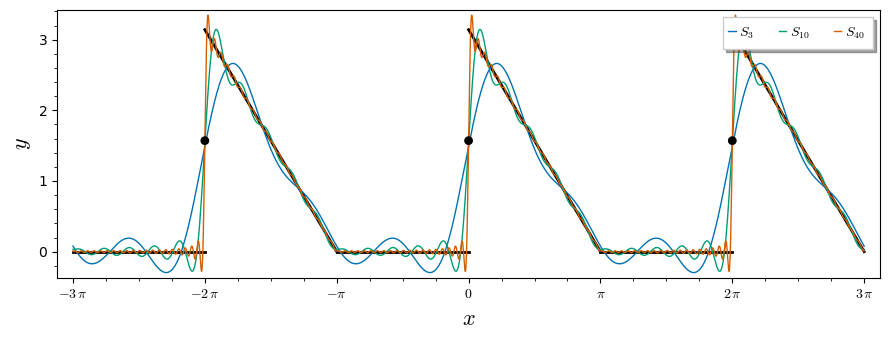

In [4]:
ramp_plot = sum(line([(2*k*pi - pi, 0), (2*k*pi, 0)], color='black', thickness=2)
                + line([(2*k*pi, pi), (2*k*pi + pi, 0)], color='black', thickness=2) for k in [-1, 0, 1])
for N, color in [(3, '#0072B2'), (10, '#009E73'), (40, '#D55E00')]:
    ramp_plot += line(list(zip(ramp_x, ramp_partial_sum(N, ramp_x))), color=color, legend_label=f'$S_{{{N}}}$')
ramp_plot += points([(2*k*pi, pi/2) for k in [-1, 0, 1]], color='black', size=40, zorder=5)
ramp_plot.show(figsize=[9, 3.5], frame=True, axes=False, axes_labels=['$x$', '$y$'],
               ticks=[pi, 1], tick_formatter=[pi, None], legend_options={'loc': 'upper right', 'ncol': 3})

**Read the picture:**  
the partial sums close in on the extension,  
and at each jump they pass through the midpoint $\frac\pi2$.  
At $\pm\pi$, where the extension is continuous with a corner,  
even $S_3$ is already close.

Next to each jump, every $S_N$ overshoots by about $9\%$ of the jump.  
With more terms, the overshoot moves closer to the jump,  
but its height does not shrink.  
This is the **Gibbs phenomenon**.  
It does not contradict the theorem, which is about one $x$ at a time.

### Example 4: a square wave

The **square wave** of period $2p$ is
$$ f(x) = \begin{cases} -1, & -p < x < 0, \\ 1, & 0 \le x < p. \end{cases} $$
Each $f(x) \cos(n\pi x/p)$ is odd,  
so every $a_n = 0$, including $a_0$:  
the average of $f$ is $0$.

For $n \ge 1$, the integrand $f(x) \sin(n\pi x/p)$ is even, so
$$ b_n = \frac2p \int_0^p \sin\frac{n\pi x}{p}\,dx = \frac{2\bigl(1 - (-1)^n\bigr)}{n\pi}. $$

Only odd $n$ appear, with $b_n = \frac4{n\pi}$:
$$ f(x) = \frac4\pi\Bigl(\sin\frac{\pi x}{p} + \frac13 \sin\frac{3\pi x}{p} + \frac15 \sin\frac{5\pi x}{p} + \cdots\Bigr). $$

If the square wave repeats $\nu$ times per second,  
it contains only the odd harmonics $\nu$, $3\nu$, $5\nu$, $\ldots$,  
with amplitudes proportional to $1$, $\frac13$, $\frac15$, $\ldots$  
The slow decay like $\frac1n$ comes from the jumps.  
In Example 1, the cosine terms add up to  
$\frac12\bigl(f(x) + f(-x)\bigr) = \frac12(\pi - |x|)$, which has no jump,  
and their coefficients decay faster, like $\frac1{n^2}$.

#### Picture: the Gibbs phenomenon for the square wave

Take $p = 1$.  
The code plots $S_N$ for three values of $N$  
and marks the height $1.179$ that their maxima approach.

In [5]:
def square_partial_sum(N, xs):
    # S_N of the square wave with p = 1: (4/pi) sum over odd n <= N of sin(n pi x)/n
    n = np.arange(1, N + 1, 2)[:, None]
    return (4/np.pi*np.sin(n*np.pi*xs)/n).sum(axis=0)
square_x = np.linspace(-1, 1, 4001)

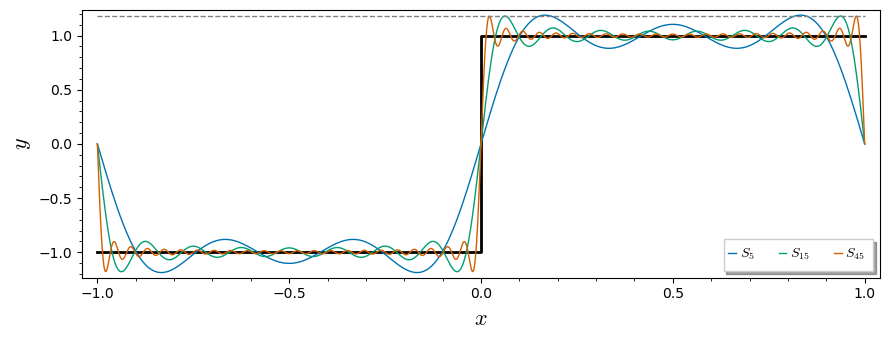

In [6]:
square_plot = line([(-1, -1), (0, -1), (0, 1), (1, 1)], color='black', thickness=2)
for N, color in [(5, '#0072B2'), (15, '#009E73'), (45, '#D55E00')]:
    square_plot += line(list(zip(square_x, square_partial_sum(N, square_x))), color=color,
                        legend_label=f'$S_{{{N}}}$')
square_plot += line([(-1, 1.179), (1, 1.179)], color='gray', linestyle='--')
square_plot.show(figsize=[9, 3.5], frame=True, axes=False, axes_labels=['$x$', '$y$'],
                 legend_options={'loc': 'lower right', 'ncol': 3})

**Read the picture:**  
the first peak of each $S_N$ sits near the dashed line $y = 1.179$,  
about $9\%$ of the jump $2$ above the value $1$.  
As $N$ grows, the peak moves toward $x = 0$  
and the wiggles away from the jump flatten out.  
At $x = \pm1$ every $S_N$ is $0$,  
the midpoint of the jump of the periodic extension.

### Summary

| Task | Tool |
|---|---|
| Inner product on $[a, b]$ | $(f, g) = \int_a^b f(x) g(x)\,dx$, with a weight: $\int_a^b w f g\,dx$ |
| Check orthogonality | odd integrands, product-to-sum identities, or the differential equation |
| Coefficient in an orthogonal expansion | $c_n = (f, \phi_n)/\lVert\phi_n\rVert^2$ |
| Fourier coefficients on $(-p, p)$ | $a_n = \frac1p \int_{-p}^p f \cos\frac{n\pi x}{p}\,dx$, $b_n = \frac1p \int_{-p}^p f \sin\frac{n\pi x}{p}\,dx$ |
| Value of the series at a jump | $\frac12\bigl(f(x+) + f(x-)\bigr)$; at $\pm p$, $\frac12\bigl(f(p-) + f(-p+)\bigr)$ |
| Numerical series | evaluate a Fourier series at a well-chosen $x$ |

### Practice habits for Fourier series

- Compute $a_0$ separately; the formula for $a_n$ often fails at $n = 0$.
- Split the integral where $f$ changes formula.
- Simplify $\cos n\pi = (-1)^n$ and $\sin n\pi = 0$ before collecting terms.
- Look for odd integrands on $[-p, p]$; their integrals are $0$.
- At a jump, or at $\pm p$, the series converges to the midpoint,  
  not to the value of $f$.

### Exam vocabulary

| Phrase | 中文 | What to write |
|---|---|---|
| **inner product** | 內積 | $(f_1, f_2) = \int_a^b f_1 f_2\,dx$ |
| **orthogonal**, **orthogonal set** | 正交、正交集 | $(\phi_m, \phi_n) = 0$ for $m \ne n$ |
| **norm**, **orthonormal** | 範數、標準正交 | $\lVert\phi\rVert = \sqrt{(\phi, \phi)}$; every norm is $1$ |
| **weight function** | 權函數 | $\int_a^b w \phi_m \phi_n\,dx = 0$ for $m \ne n$ |
| **complete** | 完備 | only $0$ is orthogonal to every $\phi_n$ |
| **Fourier series**, **Fourier coefficients** | 傅立葉級數、傅立葉係數 | $\frac{a_0}{2} + \sum \bigl(a_n \cos\frac{n\pi x}{p} + b_n \sin\frac{n\pi x}{p}\bigr)$ |
| **piecewise continuous** | 分段連續 | finitely many jumps, finite one-sided limits |
| **periodic extension** | 週期延拓 | repeat $f$ every $2p$ |
| **Gibbs phenomenon** | 吉布斯現象 | overshoot of about $9\%$ of a jump |

## Checking Worked Solutions with Sage

Sage integrates exactly,  
so it can check every coefficient above.  
The checks recompute the integrals from their definitions  
without using the answers found by hand.

In [7]:
inner = lambda f, g, a, b, w=1: integrate(w*f*g, x, a, b)
assert inner(x**2, x**3, -1, 1) == 0 and inner(x**2, x**4, -1, 1) == 2/7    # 11.1 Ex 1
assert inner(x**2, x**3, 0, 1) == 1/6
for m in range(6):                                                          # 11.1 Ex 2, Ex 3
    for n in range(6):
        assert inner(cos(m*x), cos(n*x), -pi, pi) == (0 if m != n else 2*pi if n == 0 else pi)
print('11.1 Examples 1-3 agree.')

11.1 Examples 1-3 agree.


In [8]:
P = [1, x, (3*x**2 - 1)/2, (5*x**3 - 3*x)/2]                    # 11.1 Ex 4
T = [1, x, 2*x**2 - 1, 4*x**3 - 3*x]                            # 11.1 Ex 5
for n in range(4):
    assert (P[n] - legendre_P(n, x)).expand() == 0 and (T[n] - chebyshev_T(n, x)).expand() == 0
    for m in range(n):
        assert inner(P[m], P[n], -1, 1) == 0 and inner(T[m], T[n], -1, 1, 1/sqrt(1 - x**2)) == 0
c = [inner(x**2, P[n], -1, 1)/inner(P[n], P[n], -1, 1) for n in range(4)]   # 11.1 Ex 6
assert c == [1/3, 0, 2/3, 0]
print('11.1 Examples 4-6 agree; x^2 =', ' + '.join(f'({c[n]}) P_{n}' for n in range(4) if c[n]))

11.1 Examples 4-6 agree; x^2 = (1/3) P_0 + (2/3) P_2


In [9]:
ramp = lambda g: integrate((pi - x)*g, x, 0, pi)/pi             # 11.2 Ex 1, f = 0 on (-pi, 0)
assert ramp(1)/2 == pi/4
for n in range(1, 9):
    assert ramp(cos(n*x)) == (1 - (-1)**n)/(n**2*pi) and ramp(sin(n*x)) == 1/n
p = SR.var('p'); assume(p > 0)                                  # 11.2 Ex 4, the square wave
for n in range(1, 9):
    square_b = (integrate(sin(n*pi*x/p), x, 0, p) - integrate(sin(n*pi*x/p), x, -p, 0))/p
    assert (square_b - 2*(1 - (-1)**n)/(n*pi)).simplify_full() == 0
print('11.2 Examples 1 and 4 agree.')

11.2 Examples 1 and 4 agree.


In [10]:
k = SR.var('k')
print('sum over odd n of 1/n^2 =', sum(1/(2*k + 1)**2, k, 0, oo), '  sum of 1/n^2 =', sum(1/k**2, k, 1, oo))
print('S_N(0) of Example 1, N = 1000:', ramp_partial_sum(1000, np.array([0.0]))[0], '  pi/2 =', float(pi/2))

sum over odd n of 1/n^2 = 1/8*pi^2   sum of 1/n^2 = 1/6*pi^2
S_N(0) of Example 1, N = 1000: 1.5704780170148158   pi/2 = 1.5707963267948966


The peak of the square wave's $S_N$ near $0^+$ approaches  
$\frac2\pi \int_0^\pi \frac{\sin t}{t}\,dt$;  
the ramp of Example 1 has a jump of $\pi$ instead of $2$,  
so its overshoot is $\frac\pi2$ times as large.

In [11]:
gibbs = float(2/pi*sin_integral(pi))
for N in [45, 135, 405]:
    fine_x = np.linspace(0, 0.2, 20001)
    square_peak = square_partial_sum(N, fine_x).max()
    ramp_peak = ramp_partial_sum(N, np.pi*fine_x).max()
    print(f'N = {N}:  square wave peak {square_peak:.4f},  ramp overshoot {ramp_peak - np.pi:.4f}')
print(f'limits: {gibbs:.4f} and {(gibbs - 1)*np.pi/2:.4f}, that is, {(gibbs - 1)/2:.1%} of each jump')

N = 45:  square wave peak 1.1791,  ramp overshoot 0.2138


N = 135:  square wave peak 1.1790,  ramp overshoot 0.2583


N = 405:  square wave peak 1.1790,  ramp overshoot 0.2735
limits: 1.1790 and 0.2811, that is, 8.9% of each jump


## Homework Due Sunday

Turn in the problem with only one dot after \letter\number.

### Orthogonal functions

For A1–A4, show that the two functions  
are orthogonal on the given interval.

A1. $x$ and $x^2$ on $[-2, 2]$.  
A2.. $e^x$ and $xe^{-x} - e^{-x}$ on $[0, 2]$.  
A3. $\cos x$ and $\sin(x)^2$ on $[0, \pi]$.  
A4. $e^x$ and $\sin x$ on $[\frac\pi4, \frac{5\pi}4]$.

A5. Find constants $c_1$ and $c_2$  
such that $x + c_1 x^2 + c_2 x^3$  
is orthogonal to both $x$ and $x^2$ on $[-2, 2]$.

### Orthogonal sets and norms

For B1–B3, show that the set is orthogonal on the given interval,  
and find the norm of each member.

B1. $\{\sin x, \sin3x, \sin5x, \ldots\}$ on $[0, \frac\pi2]$.  
B2. $\{\sin(n\pi x/p)\}_{n=1}^\infty$ on $[0, p]$.  
B3.. $\{1, \cos(n\pi x/p)\}_{n=1}^\infty$ on $[0, p]$.

B4. Show that $H_0 = 1$, $H_1 = 2x$, $H_2 = 4x^2 - 2$  
are orthogonal with respect to $w(x) = e^{-x^2}$ on $(-\infty, \infty)$.  
You may use $\int_{-\infty}^\infty e^{-x^2}\,dx = \sqrt\pi$.  
B5. Show that $L_0 = 1$, $L_1 = 1 - x$, $L_2 = \frac12 x^2 - 2x + 1$  
are orthogonal with respect to $w(x) = e^{-x}$ on $[0, \infty)$.

B6. Let $\{\phi_n\}$ be orthogonal on $[a, b]$ with $\phi_0 = 1$.  
Show that $\int_a^b \phi_n(x)\,dx = 0$ for $n \ge 1$.  
B7. Let $\{\phi_n\}$ be orthogonal on $[a, b]$.  
Show that $\|\phi_m + \phi_n\|^2 = \|\phi_m\|^2 + \|\phi_n\|^2$ for $m \ne n$.

### Expansions and completeness

C1. Expand $x^3$ on $[-1, 1]$ in Legendre polynomials,  
using $c_n = (f, P_n)/\|P_n\|^2$, and check your answer.  
C2.. Among all lines $b_0 + b_1 x$,  
find the one closest to $e^x$ on $[-1, 1]$,  
in the sense that $\|e^x - b_0 - b_1 x\|$ is smallest.  
Compare it with the Taylor polynomial $1 + x$.

C3. Show that $\{\sin nx\}_{n=1}^\infty$ is orthogonal on $[-\pi, \pi]$  
but not complete in the continuous functions on $[-\pi, \pi]$.

## Homework Due Wednesday

Turn in the problem with only one dot after \letter\number.

### Fourier series

For D1–D6, find the Fourier series of $f$ on the given interval,  
and give the value of the series at each jump in $(-p, p)$ and at $\pm p$.

D1. $f(x) = 0$ on $(-\pi, 0)$, $1$ on $[0, \pi)$.  
D2. $f(x) = 0$ on $(-1, 0)$, $x$ on $[0, 1)$.  
D3. $f(x) = x + \pi$ on $(-\pi, \pi)$.

D4. $f(x) = 0$ on $(-\pi, 0)$, $\sin x$ on $[0, \pi)$.  
D5. $f(x) = 1$ on $(-5, 0)$, $1 + x$ on $[0, 5)$.  
D6.. $f(x) = e^x$ on $(-\pi, \pi)$.

### Numerical series

E1. Evaluate the series of D3 at $x = \frac\pi2$ to show that
$$ \frac\pi4 = 1 - \frac13 + \frac15 - \frac17 + \cdots. $$

E2. Evaluate the series of D4 at $x = \frac\pi2$ to show that
$$ \frac\pi4 = \frac12 + \frac1{1 \cdot 3} - \frac1{3 \cdot 5} + \frac1{5 \cdot 7} - \cdots. $$

E3. Find the Fourier series of $x^2$ on $(-\pi, \pi)$.  
Evaluate it at $x = 0$ and at $x = \pi$  
to find $\sum_{n=1}^\infty \frac{(-1)^{n+1}}{n^2}$
and $\sum_{n=1}^\infty \frac1{n^2}$.

### Periodic extension

F1. Write the fundamental period, the smallest period $T > 0$, of

(a) $\cos2\pi x$; (b) $\sin\frac{4x}{L}$; (c) $\sin x + \sin2x$;  
(d) $\sin2x + \cos4x$; (e) $\sin3x + \cos2x$;  
(f) $A_0 + \sum_{n\ge1} \bigl(A_n \cos(n\pi x/p) + B_n \sin(n\pi x/p)\bigr)$,  
with $B_1 \ne 0$.

F2. Sketch the function to which the series of D5 converges  
on $(-15, 15)$, marking its value at every jump.  
F3.. Sketch the same for D4 on $(-3\pi, 3\pi)$,  
and explain in one line why the series converges to $f$ at every $x$.

### Complex form

G1.. Use $\cos\theta = \frac12(e^{i\theta} + e^{-i\theta})$  
and $\sin\theta = \frac1{2i}(e^{i\theta} - e^{-i\theta})$  
to write the Fourier series as
$\sum_{n=-\infty}^\infty c_n e^{in\pi x/p}$, where
$$ c_n = \frac1{2p} \int_{-p}^p f(x) e^{-in\pi x/p}\,dx, \qquad n = 0, \pm1, \pm2, \ldots. $$
Express $c_0$, $c_n$, $c_{-n}$ in terms of $a_n$ and $b_n$.

G2.. Find the complex form of the Fourier series  
of $e^{-x}$ on $(-\pi, \pi)$.